[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ivanvladimir/maquinas_notebooks/blob/main/lfya/04%20Abro%20par%C3%A9ntesis%2C%20abro%20par%C3%A9ntesis%2C%20cierro%20par%C3%A9ntesis.ipynb)


# 04 Abro paréntesis, abro paréntesis, cierro paréntesis

Esta notebook ilustra los conceptos de [**abro paréntesis, abro paréntesis, cierro paréntesis**](04 Abro paréntesis, abro paréntesis, cierro paréntesis) correspondiente al curso de [**Lenguajes Formales y Autómatas**](https://turing.iimas.unam.mx/~ivanvladimir/page/curso_lfya/)


## Instrucciones

1. Si la librería [**maquinas**](https://pypi.org/project/maquinas/) no está instalada ejecutar la celdas correspondiente a la sección marcada con ◉
2. Importar los módulos de librería relevantes
3. Ejecuar las celdas para explorar los conceptos


## Licencia de la notebook

<a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Creative Commons License" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a>
</br>This work is licensed under a <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Creative Commons Attribution 4.0 International License</a>.

## General information

> **Author(s)**: <a href="https://twitter.com/ivanvladimir">@ivanvladimir</a></br>
> **Last updated**: 24/01/2023

## 00 Instalando la librería 

Se instala la librería [maquinas](https://pypi.org/project/maquinas/)

**Requerido en colab**, _opcional en ambiente local a través de jupyter_

In [13]:
# Execute if not installes
!pip install maquinas --upgrade

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

### 01 Importar módulo para cargar gramáticas libres de contexto y funciones auxiliares

Existen dos elemento: _load_fa_, _las reducciones_, el proceso de _minimización_, _RE_ y _Simulation_ (en este momento _Simulación_ sólo puede ir hacia adelante)

In [1]:
from maquinas.contextfree.cfg import ContextFreeGrammar as CFG
from maquinas.parser.earley_parser import print_chart, chart2table

## 02 Gramática libres de contexto

Para crear una gramática se puede crear directamente desde la clase _ContextFreeGrammar_

In [2]:
aⁿbⁿ=CFG("S->aSb; S-> epsilon;")
aⁿbⁿ.print_summary()

No terminal : S
Terminals   : a, b
Start       : S
Productions :
 S → aSb | ε

### 02.a "Parseo" análisis de una cadena

Para analizar una cadena _w_, se le usa el método de _parse_; y regresa tres objetos:
    
    * roots, los símbolos iniciales 
    * chart, el _chart parser_ del proceso de análisis de la cadena
    * forest, los áboles con nodos compartidos _tree_
    
Para extraer los árboles se hace con la función _extract_tree_; y regresa un iterator sobre los árboles. Para producir la derivación, paso a paso, es posible extraerla con la función _derivación_;

In [3]:
# Analysis de cadena
roots,chart,forest=aⁿbⁿ.parse('aaaabbbb')
# Extrae árboles
trees=aⁿbⁿ.extract_trees(forest)
# Identifica el primer arból
tree=list(trees)[0]
for i,step in enumerate(aⁿbⁿ.derivation(tree)):
    if not i:
        print("".join(step),end="")
    else:
        print(" ⇒ ","".join(step),end="\n ")

S ⇒  aSb
  ⇒  aaSbb
  ⇒  aaaSbbb
  ⇒  aaaaSbbbb
  ⇒  aaaabbbb
 

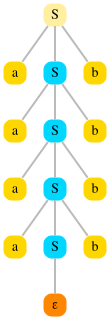

In [4]:
aⁿbⁿ.graph_tree(tree)

In [5]:
for i in range(11):
    a='a'*i
    b='b'*i
    ab=a+b
    print("Derivation: ",ab)
    if len(ab)==0:
        ab=""
    roots,chart,forest=aⁿbⁿ.parse(ab)
    trees=aⁿbⁿ.extract_trees(forest)
    for i,step in enumerate(aⁿbⁿ.derivation(list(trees)[0])):
        if not i:
            print("".join(step),end="")
        else:
            print(" ⇒ ","".join(step),end="\n ")   

Derivation:  
S ⇒  ε
 Derivation:  ab
S ⇒  aSb
  ⇒  ab
 Derivation:  aabb
S ⇒  aSb
  ⇒  aaSbb
  ⇒  aabb
 Derivation:  aaabbb
S ⇒  aSb
  ⇒  aaSbb
  ⇒  aaaSbbb
  ⇒  aaabbb
 Derivation:  aaaabbbb
S ⇒  aSb
  ⇒  aaSbb
  ⇒  aaaSbbb
  ⇒  aaaaSbbbb
  ⇒  aaaabbbb
 Derivation:  aaaaabbbbb
S ⇒  aSb
  ⇒  aaSbb
  ⇒  aaaSbbb
  ⇒  aaaaSbbbb
  ⇒  aaaaaSbbbbb
  ⇒  aaaaabbbbb
 Derivation:  aaaaaabbbbbb
S ⇒  aSb
  ⇒  aaSbb
  ⇒  aaaSbbb
  ⇒  aaaaSbbbb
  ⇒  aaaaaSbbbbb
  ⇒  aaaaaaSbbbbbb
  ⇒  aaaaaabbbbbb
 Derivation:  aaaaaaabbbbbbb
S ⇒  aSb
  ⇒  aaSbb
  ⇒  aaaSbbb
  ⇒  aaaaSbbbb
  ⇒  aaaaaSbbbbb
  ⇒  aaaaaaSbbbbbb
  ⇒  aaaaaaaSbbbbbbb
  ⇒  aaaaaaabbbbbbb
 Derivation:  aaaaaaaabbbbbbbb
S ⇒  aSb
  ⇒  aaSbb
  ⇒  aaaSbbb
  ⇒  aaaaSbbbb
  ⇒  aaaaaSbbbbb
  ⇒  aaaaaaSbbbbbb
  ⇒  aaaaaaaSbbbbbbb
  ⇒  aaaaaaaaSbbbbbbbb
  ⇒  aaaaaaaabbbbbbbb
 Derivation:  aaaaaaaaabbbbbbbbb
S ⇒  aSb
  ⇒  aaSbb
  ⇒  aaaSbbb
  ⇒  aaaaSbbbb
  ⇒  aaaaaSbbbbb
  ⇒  aaaaaaSbbbbbb
  ⇒  aaaaaaaSbbbbbbb
  ⇒  aaaaaaaaSbbbbbbbb
  ⇒  aaaaaaaaa

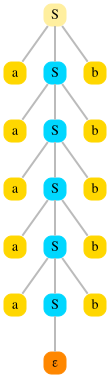

In [6]:
roots,chart,forest=aⁿbⁿ.parse("aaaaabbbbb")
trees=aⁿbⁿ.extract_trees(forest)
aⁿbⁿ.graph_trees(trees)

### 2.b Creando una gramática para cadenas que representen expresiones regulares

La siguiente gramática representa a ER para el alfabeto 

$$\Sigma=\{a,b\}$$

In [7]:
re=CFG('R->B; R-> R "+" R; R -> R "*"; R-> RR; R->(R); B-> a; B -> b; B -> "ϵ"; B -> "∅"')
re.print_summary()

No terminal : R, B
Terminals   : +, *, (, ), a, b, ϵ, ∅
Start       : R
Productions :
 R → B | R+R | R* | RR | (R)
 B → a | b | ϵ | ∅

In [8]:
roots,chart,forest=re.parse('(a*ba*ba*)*')
trees=list(re.extract_trees(forest))
for i,step in enumerate(re.derivation(trees[0])):
    if not i:
        print("".join(step),end="")
    else:
        print(" ⇒ ","".join(step),end="\n ")

R ⇒  R*
  ⇒  (R)*
  ⇒  (RR)*
  ⇒  (RRR)*
  ⇒  (R*RR)*
  ⇒  (B*RR)*
  ⇒  (a*RR)*
  ⇒  (a*BR)*
  ⇒  (a*bR)*
  ⇒  (a*bR*)*
  ⇒  (a*bRR*)*
  ⇒  (a*bRRR*)*
  ⇒  (a*bR*RR*)*
  ⇒  (a*bB*RR*)*
  ⇒  (a*ba*RR*)*
  ⇒  (a*ba*BR*)*
  ⇒  (a*ba*bR*)*
  ⇒  (a*ba*bB*)*
  ⇒  (a*ba*ba*)*
 

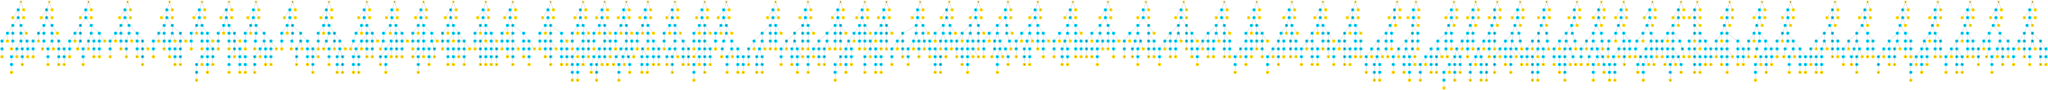

In [9]:
re.graph_trees(trees)

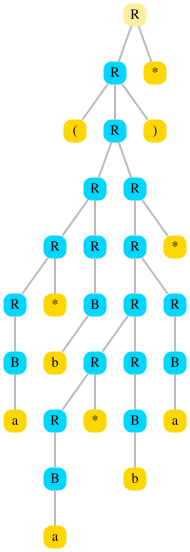

In [10]:
re.graph_tree(trees[0])

In [11]:
print("Total number of trees",len(trees))

Total number of trees 66
